In [ ]:
import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder


from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [ ]:
df = pd.read_csv("D:\ML_Lab\SuperMarket Analysis.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


Dataset Shape: (1000, 17)

First 5 rows:
    Invoice ID Branch       City Customer type  Gender  \
0  750-67-8428   Alex     Yangon        Member  Female   
1  226-31-3081   Giza  Naypyitaw        Normal  Female   
2  631-41-3108   Alex     Yangon        Normal  Female   
3  123-19-1176   Alex     Yangon        Member  Female   
4  373-73-7910   Alex     Yangon        Member  Female   

             Product line  Unit price  Quantity   Tax 5%     Sales       Date  \
0       Health and beauty       74.69         7  26.1415  548.9715   1/5/2019   
1  Electronic accessories       15.28         5   3.8200   80.2200   3/8/2019   
2      Home and lifestyle       46.33         7  16.2155  340.5255   3/3/2019   
3       Health and beauty       58.22         8  23.2880  489.0480  1/27/2019   
4       Sports and travel       86.31         7  30.2085  634.3785   2/8/2019   

          Time      Payment    cogs  gross margin percentage  gross income  \
0   1:08:00 PM      Ewallet  522.83          

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [ ]:
median_sales = df["Sales"].median()

df["Sales_Class"] = (df["Sales"] >= median_sales).astype(int)

print("\nMedian Sales:", median_sales)

print("\nClass Distribution:")
print(df["Sales_Class"].value_counts())


Median Sales: 253.848

Class Distribution:
Sales_Class
1    500
0    500
Name: count, dtype: int64


In [ ]:
features = [
    "Branch",
    "City",
    "Customer type",
    "Gender",
    "Product line",
    "Unit price",
    "Quantity",
    "Tax 5%",
    "Payment",
    "cogs",
    "gross margin percentage",
    "gross income",
    "Rating"
]

X = df[features].copy()
y = df["Sales_Class"]

In [ ]:
categorical_columns = X.select_dtypes(include=["object"]).columns
X = pd.get_dummies(X,columns=categorical_columns,drop_first=True)
print("\nFeatures after encoding:", X.shape)



Features after encoding: (1000, 20)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 800
Testing samples: 200


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
models = {

    "SVM - Linear": SVC(
        kernel="linear",
        random_state=42
    ),

    "SVM - Polynomial": SVC(
        kernel="poly",
        degree=3,
        random_state=42
    ),

    "SVM - RBF": SVC(
        kernel="rbf",
        random_state=42
    ),
    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Naive Bayes": GaussianNB()
}

In [ ]:
results = []

for name, model in models.items():


    model.fit(X_train_scaled, y_train)

    
    y_pred = model.predict(X_test_scaled)


    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })


In [ ]:
results_df = pd.DataFrame(results)

print("\n================ MODEL COMPARISON ================\n")

print(
    results_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4f}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1 Score": "{:.4f}".format
        }
    )
)


================ MODEL COMPARISON ================

           Model Accuracy Precision Recall F1 Score
    SVM - Linear   0.9800    0.9800 0.9800   0.9800
SVM - Polynomial   0.9650    0.9515 0.9800   0.9655
       SVM - RBF   0.9600    0.9694 0.9500   0.9596
             KNN   0.8850    0.9053 0.8600   0.8821
   Decision Tree   1.0000    1.0000 1.0000   1.0000
     Naive Bayes   0.9950    1.0000 0.9900   0.9950


In [ ]:
results_percentage = results_df.copy()

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

results_percentage[metric_columns] *= 100

print("\n================ RESULTS IN PERCENTAGE ================\n")

print(
    results_percentage.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.2f}%".format,
            "Precision": "{:.2f}%".format,
            "Recall": "{:.2f}%".format,
            "F1 Score": "{:.2f}%".format
        }
))


================ RESULTS IN PERCENTAGE ================

           Model Accuracy Precision  Recall F1 Score
    SVM - Linear   98.00%    98.00%  98.00%   98.00%
SVM - Polynomial   96.50%    95.15%  98.00%   96.55%
       SVM - RBF   96.00%    96.94%  95.00%   95.96%
             KNN   88.50%    90.53%  86.00%   88.21%
   Decision Tree  100.00%   100.00% 100.00%  100.00%
     Naive Bayes   99.50%   100.00%  99.00%   99.50%


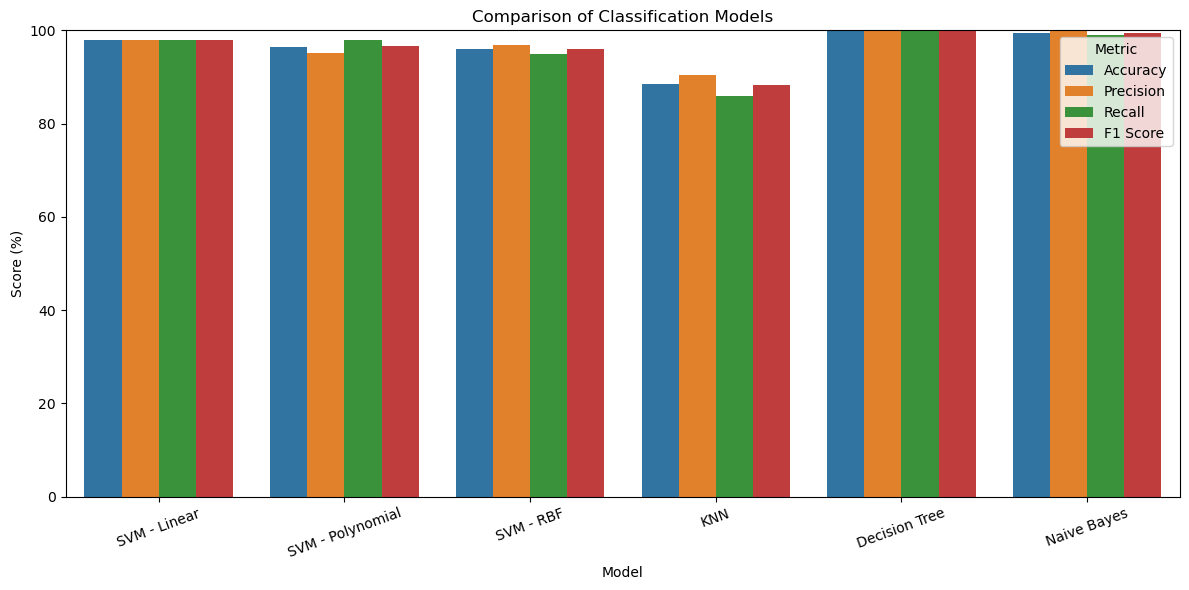

In [ ]:
results_melted = results_percentage.melt(
    id_vars="Model",
    value_vars=metric_columns,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 100)

plt.xticks(rotation=20)

plt.legend(title="Metric")

plt.tight_layout()
plt.show()


In [ ]:
for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    print("\n")
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Low Sales",
                "High Sales"
            ],
            zero_division=0
        )
    )



SVM - Linear
              precision    recall  f1-score   support

   Low Sales       0.98      0.98      0.98       100
  High Sales       0.98      0.98      0.98       100

    accuracy                           0.98       200
   macro avg       0.98      0.98      0.98       200
weighted avg       0.98      0.98      0.98       200



SVM - Polynomial
              precision    recall  f1-score   support

   Low Sales       0.98      0.95      0.96       100
  High Sales       0.95      0.98      0.97       100

    accuracy                           0.96       200
   macro avg       0.97      0.96      0.96       200
weighted avg       0.97      0.96      0.96       200



SVM - RBF
              precision    recall  f1-score   support

   Low Sales       0.95      0.97      0.96       100
  High Sales       0.97      0.95      0.96       100

    accuracy                           0.96       200
   macro avg       0.96      0.96      0.96       200
weighted avg       0.96     


SVM - Linear
[[98  2]
 [ 2 98]]


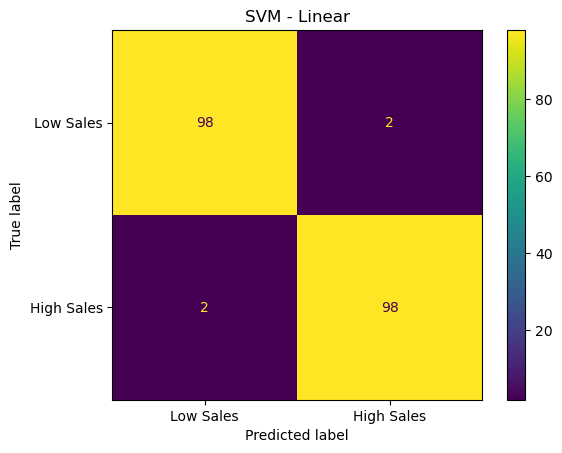


SVM - Polynomial
[[95  5]
 [ 2 98]]


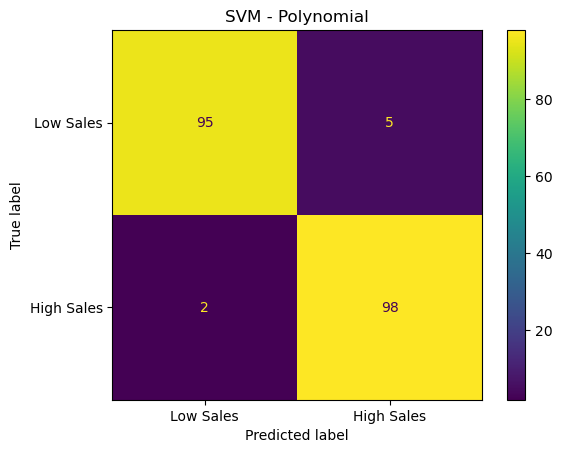


SVM - RBF
[[97  3]
 [ 5 95]]


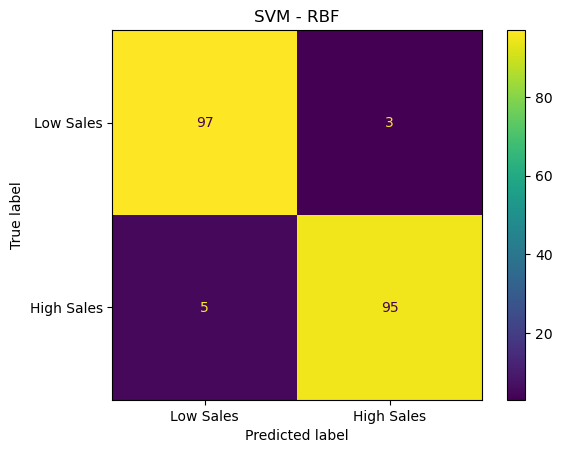


KNN
[[91  9]
 [14 86]]


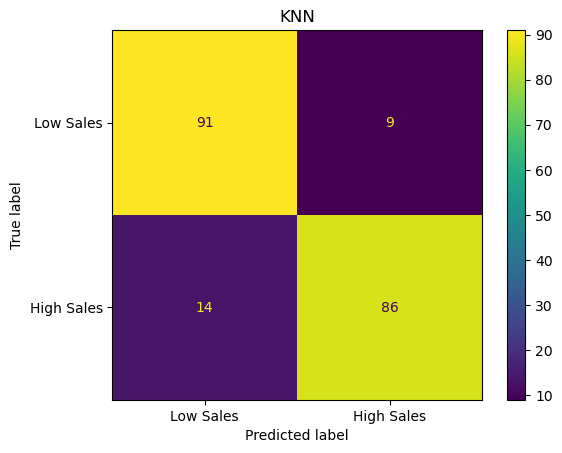


Decision Tree
[[100   0]
 [  0 100]]


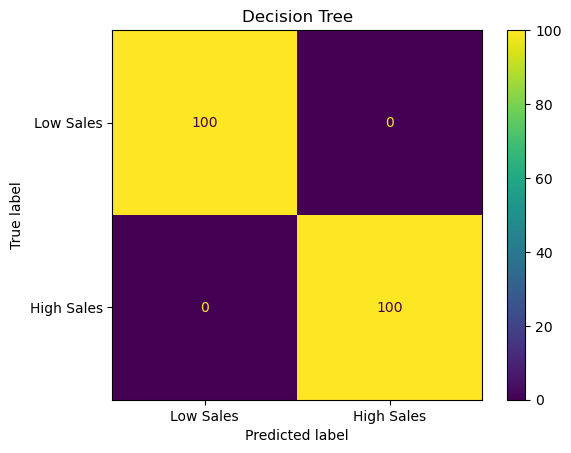


Naive Bayes
[[100   0]
 [  1  99]]


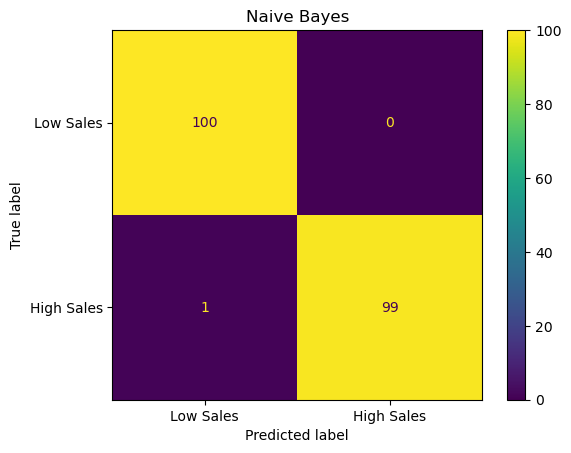

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in models.items():

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Low Sales", "High Sales"]
    ).plot()

    plt.title(name)
    plt.show()